# 04 - Features físicas (estadísticos, FFT y BLS)

Las funciones están en `src/features.py`; el cálculo masivo lo hace `scripts/compute_features.py` (guarda `results/features_train.csv` y `results/features_test.csv`).

Supuestos: cadencia uniforme de 30 min (el dataset no trae tiempos) y búsqueda BLS de períodos entre 0,5 y 30 días (la curva dura ~66 días; se necesitan al menos 2 tránsitos para definir un período).

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import BoxLeastSquares
from src.data import load_split
from src.preprocessing import preprocess
from src.features import PERIODS, DURATIONS, CADENCE_MIN

pd.set_option('display.width', 200)
X, y = load_split('train')
ESTRELLAS = {18: 'con planeta', 28: 'con planeta', 243: 'sin planeta'}
Z = preprocess(X[list(ESTRELLAS)])
t = np.arange(X.shape[1]) * CADENCE_MIN / (60 * 24)
print('duración de la curva: %.1f días' % t[-1])

duración de la curva: 66.6 días


## 1. Ejemplo visual: curva, espectro FFT y plegado BLS

Para cada estrella: (arriba) la curva preprocesada; (centro) su espectro de potencia FFT; (abajo) la curva **plegada** con el período que encontró el BLS: si el período es correcto, todas las caídas se apilan en el mismo lugar y se ve una "caja" de brillo bajo.

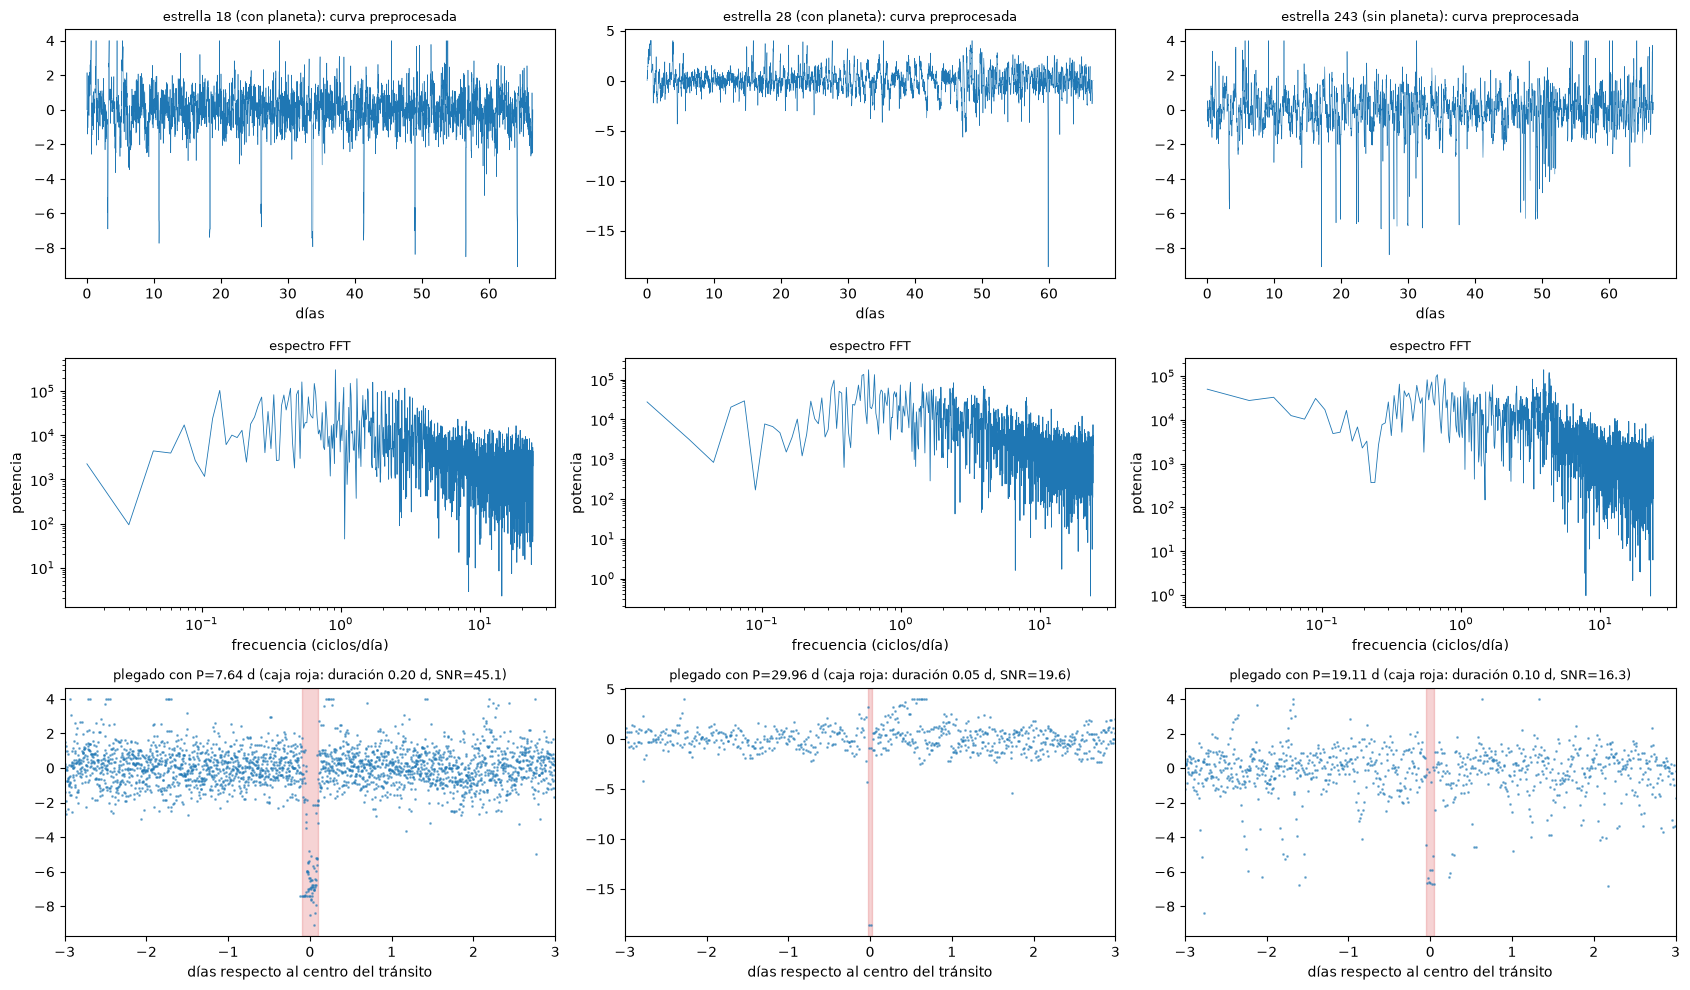

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(17, 10))
for col, (idx, z) in enumerate(zip(ESTRELLAS, Z)):
    etiqueta = ESTRELLAS[idx]
    # 1) curva
    axes[0, col].plot(t, z, lw=0.4)
    axes[0, col].set_title(f'estrella {idx} ({etiqueta}): curva preprocesada', fontsize=9)
    axes[0, col].set_xlabel('días')
    # 2) FFT
    freqs = np.fft.rfftfreq(len(z), d=CADENCE_MIN / (60 * 24))[1:]
    pot = np.abs(np.fft.rfft(z - z.mean())) ** 2
    axes[1, col].loglog(freqs, pot[1:], lw=0.6)
    axes[1, col].set_title('espectro FFT', fontsize=9)
    axes[1, col].set_xlabel('frecuencia (ciclos/día)')
    axes[1, col].set_ylabel('potencia')
    # 3) BLS plegado
    bls = BoxLeastSquares(t, z)
    r = bls.power(PERIODS, DURATIONS, objective='snr')
    i = np.argmax(r.power)
    P, T0, D = r.period[i], r.transit_time[i], r.duration[i]
    fase = ((t - T0 + 0.5 * P) % P) - 0.5 * P
    axes[2, col].plot(fase, z, '.', ms=2, alpha=0.5)
    axes[2, col].axvspan(-D / 2, D / 2, color='tab:red', alpha=0.2)
    axes[2, col].set_xlim(-min(P / 2, 3), min(P / 2, 3))
    axes[2, col].set_title(f'plegado con P={P:.2f} d (caja roja: duración {D:.2f} d, SNR={r.power[i]:.1f})', fontsize=9)
    axes[2, col].set_xlabel('días respecto al centro del tránsito')
plt.tight_layout()
plt.savefig('../results/04_fft_bls_ejemplo.png', dpi=100)
plt.show()

**Lectura de la figura:**
- **Estrella 18 (con planeta):** el plegado con P=7,64 d apila varias caídas de ~-7 sigmas dentro de la caja roja: es un tránsito claro (SNR 45).
- **Estrella 28 (con planeta):** el BLS elige P=29,96 d (casi el límite de la búsqueda) apoyándose en una sola caída profunda cerca del día 60. Es una caída aislada, no un patrón repetido: un caso en que el BLS acierta la etiqueta por una razón débil.
- **Estrella 243 (sin planeta):** las caídas no se alinean al plegar; el SNR (16) es menor.
- **FFT:** en ninguna de las tres aparece un pico claro. Como se anticipó, un tránsito es una caída angosta, no una onda suave, y su energía se reparte en muchas frecuencias; la FFT aporta poco como detector directo.

## 2. Features calculadas para todo el dataset

In [3]:
F_train = pd.read_csv('../results/features_train.csv')
F_test = pd.read_csv('../results/features_test.csv')
print('train:', F_train.shape, '| test:', F_test.shape)
print('NaN:', F_train.isna().sum().sum(), F_test.isna().sum().sum())
F_train.groupby('label').median().T.round(3)

train: (5087, 19) | test: (570, 19)
NaN: 0 0


label,0,1
stat_min,-6.573,-7.541
stat_p1,-2.922,-3.811
stat_p5,-1.783,-2.138
stat_std,1.208,1.319
stat_skew,-0.071,-0.604
stat_kurtosis,1.924,3.224
stat_n_below_3,30.000,63.000
stat_n_below_5,3.000,16.000
fft_peak_freq,0.706,0.916
fft_peak_ratio,72.846,168.083


Mediana de cada feature, separando estrellas sin planeta (0) y con planeta (1). Una feature es útil si sus valores se parecen poco entre ambos grupos.

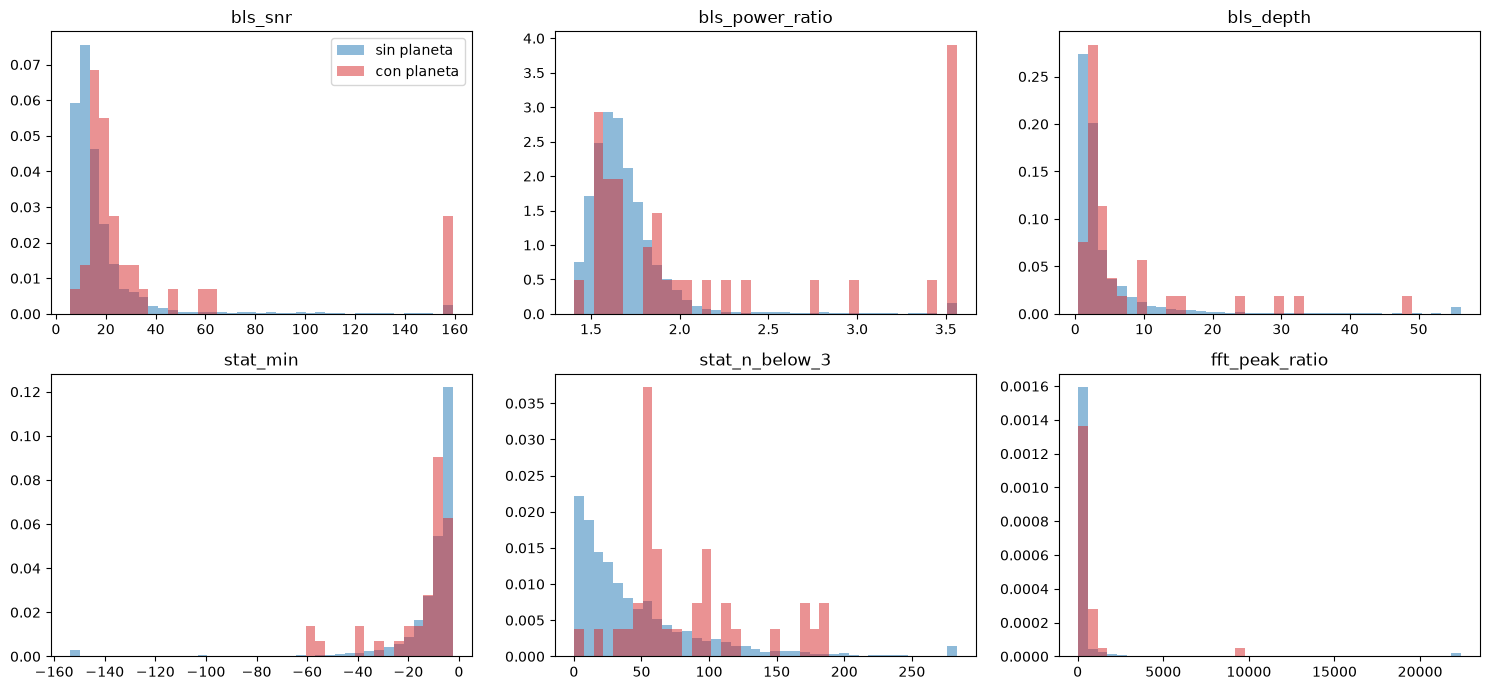

In [4]:
cols = ['bls_snr', 'bls_power_ratio', 'bls_depth', 'stat_min', 'stat_n_below_3', 'fft_peak_ratio']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cols):
    lo, hi = F_train[c].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(F_train.loc[F_train.label == 0, c].clip(lo, hi), bins=bins, density=True, alpha=0.5, label='sin planeta')
    ax.hist(F_train.loc[F_train.label == 1, c].clip(lo, hi), bins=bins, density=True, alpha=0.5, label='con planeta', color='tab:red')
    ax.set_title(c)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig('../results/04_distribucion_features.png', dpi=100)
plt.show()

In [5]:
from sklearn.metrics import average_precision_score
ap = {c: average_precision_score(F_train.label, F_train[c]) for c in F_train.columns if c != 'label'}
ap_neg = {c: average_precision_score(F_train.label, -F_train[c]) for c in F_train.columns if c != 'label'}
mejor = pd.Series({c: max(ap[c], ap_neg[c]) for c in ap}).sort_values(ascending=False)
print('PR-AUC de cada feature por sí sola (azar ~ %.4f):' % F_train.label.mean())
mejor.round(4)

PR-AUC de cada feature por sí sola (azar ~ 0.0073):


bls_power_ratio    0.0882
stat_p1            0.0306
bls_snr            0.0305
stat_p5            0.0177
stat_n_below_3     0.0173
stat_n_below_5     0.0172
stat_std           0.0155
fft_peak_ratio     0.0147
bls_period         0.0138
bls_depth          0.0131
bls_n_transits     0.0131
fft_high_frac      0.0128
stat_skew          0.0125
stat_min           0.0109
fft_low_frac       0.0104
stat_kurtosis      0.0104
fft_peak_freq      0.0097
bls_duration       0.0093
dtype: float64

**Lectura de las features:**
- Las estrellas con planeta tienen, en mediana, más puntos bajo -3 y -5 sigmas, más asimetría negativa, mayor SNR y mayor contraste en el BLS, y más tránsitos detectados (5 vs 2).
- La mejor feature por sí sola es **`bls_power_ratio`** (PR-AUC 0,088, unas 12 veces el azar de 0,0073), seguida de `stat_p1` y `bls_snr` (~0,03). Esto respalda el uso de features físicas del BLS.
- Ninguna feature separa las clases por sí sola (todas con PR-AUC < 0,1): se necesita combinarlas en un modelo (Paso 7).
- Las features de FFT son las más débiles (PR-AUC ~0,01), consistente con lo observado en la figura; el estudio de ablación medirá cuánto aportan realmente.